# Part II · Notebook 06 — Post-hoc stress tests S1–S4

Internal labels R1–R4 in code and file names correspond to stress tests S1–S4 in the paper.

| ID | Weak point of the pre-specified design | What this notebook does |
|---|---|---|
| R1 | H7 used only 5 vulnerable + 5 random targets | Record-targeted attacks on **100 targets** (50 most vulnerable + 50 random) with a shared-shadow design (Carlini et al. 2022): every release is fitted on a random half of a 1,000-record pool, so each release is an "in" or "out" example for every target at once. |
| R2 | The DP audit had no power | **Canary audit**: the target is a crafted worst-case record with rare values (standard practice in DP auditing), and 160 evaluation releases per mechanism. With 80/80 releases the audit can certify at most ε ≈ 3.0, so it can detect a violation of ε = 1 but not of ε = 10. |
| R3 | The transformer's memorisation on 300–400 rows is a model-selection problem | AR-Transformer on German and Pima with **shorter training** (a form of regularisation): 150, 300, 750 steps vs the 1,500-step default. |
| R4 | Scarcity was tested below the generators' operating range, and 5,000 synthetic rows swamped the real ones | **Fair augmentation test** at n = 500, 1,000, 2,500 real rows, adding synthetic rows at **0.5×, 1× and 2×** the real count, for six generators. Plus a re-analysis of Part I's E5 split into "below operating range" (n ≤ 250) and "operating range" (n ≥ 500). |

These analyses were designed after the pre-specified analyses, so they are reported as exploratory post-hoc stress tests, not as pre-specified tests.

In [1]:
import os, time, json, gc, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.spatial.distance import cdist
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import false_discovery_control
import sdaudit as sa
QUICK = os.environ.get("QUICK", "0") == "1"
if QUICK: sa.CFG.update(ctgan_epochs=3, tvae_epochs=3, ddpm_steps=50, ar_steps=30)
OUT = "outputs2"; T = f"{OUT}/tables"; os.makedirs(T, exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
T0 = time.time()
df, meta = sa.load("adult")

## R1. Targeted attacks on 100 records
Pool: 1,000 Adult records = 50 most vulnerable + 50 random records from a 5,000-record reference sample, plus 900 other records.
Each release: the generator is fitted on a random 500 of the 1,000 (so each target is "in" with probability ½) and releases 500 rows.
100 releases train one attack classifier per target; 100 fresh releases evaluate it (≈ 50 in / 50 out per target).

In [2]:
rs = np.random.RandomState(7)
ref = df.iloc[rs.choice(len(df), 5000, replace=False)].reset_index(drop=True)
v = sa.vulnerability(ref, meta)
vul = np.argsort(-v)[:50]; rnd = rs.choice(np.setdiff1d(np.arange(len(ref)), vul), 50, replace=False)
targets = pd.concat([ref.iloc[vul], ref.iloc[rnd]]).reset_index(drop=True); kinds = np.array(["vulnerable"] * 50 + ["random"] * 50)
others = df.drop(index=df.index[df.apply(tuple, axis=1).isin(targets.apply(tuple, axis=1))]).sample(900, random_state=7)
POOL = pd.concat([targets, others]).reset_index(drop=True); NT = len(targets)
for c in meta["num"]: POOL[c] = POOL[c].astype(float)
enc = sa.Encoder(POOL, meta)
qb = {c: np.unique(np.quantile(df[c], np.linspace(0.1, 0.9, 9))) for c in meta["num"]}
def codes(d):
    return np.stack([np.digitize(d[c].values, qb[c]) if c in meta["num"] else pd.Categorical(d[c], categories=sorted(df[c].unique())).codes for c in POOL.columns], 1)
Ct = codes(targets); Et = enc(targets)
SUBS = [[list(np.random.RandomState(1000 * t + k).choice(len(POOL.columns), np.random.RandomState(1000 * t + k).randint(1, 4), replace=False)) for k in range(20)] for t in range(NT)]
def features(syn):
    E = enc(syn); D = cdist(Et, E); C = codes(syn); F = np.zeros((NT, 26))
    for i, r in enumerate([0.05, 0.1, 0.25, 0.5]): F[:, i] = (D <= r).mean(1)
    F[:, 4] = D.min(1); F[:, 5] = np.sort(D, 1)[:, :5].mean(1)
    for t in range(NT):
        for k, sub in enumerate(SUBS[t]): F[t, 6 + k] = np.all(C[:, sub] == Ct[t, sub], axis=1).mean()
    return F
N_REL = {"Independent": 200, "GaussianCopula": 200, "CART": 200, "TVAE": 200, "CTGAN": 120} if not QUICK else {"CART": 20, "TVAE": 12}
def one_release(g, r):
    rr = np.random.RandomState(10_000 + r); idx = rr.choice(len(POOL), 500, replace=False); inm = np.zeros(len(POOL), bool); inm[idx] = True
    D = POOL.iloc[idx].reset_index(drop=True)
    syn = sa.postprocess(sa.GENERATORS[g](D, meta, 10_000 + r, n=500), D, meta)
    return features(syn), inm[:NT]
R1 = []
for g, nrel in N_REL.items():
    t0 = time.time()
    res = Parallel(n_jobs=2 if g in ("Independent", "GaussianCopula", "CART") else 1)(delayed(one_release)(g, r) for r in range(nrel))
    F = np.stack([a for a, _ in res]); L = np.stack([b for _, b in res]); half = nrel // 2
    for t in range(NT):
        Xtr, ytr, Xte, yte = F[:half, t], L[:half, t], F[half:, t], L[half:, t]
        if len(np.unique(ytr)) < 2 or len(np.unique(yte)) < 2: continue
        s = RandomForestClassifier(200, min_samples_leaf=2, random_state=t).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        bb = -Xte[:, 4]
        R1.append(dict(generator=g, target=t, kind=kinds[t], vulnerability=float(v[vul[t]] if t < 50 else v[rnd[t - 50]]),
                       auc=roc_auc_score(yte, s), bb_auc=roc_auc_score(yte, bb), n_eval=len(yte),
                       p=stats.mannwhitneyu(s[yte], s[~yte], alternative="greater").pvalue))
    pd.DataFrame(R1).to_csv(f"{T}/R1_targets100.csv", index=False)
    print(f"{g:<15} {nrel} releases | {time.time()-t0:.0f}s", flush=True)
R1 = pd.DataFrame(R1)
R1["p_bh"] = R1.groupby("generator").p.transform(lambda p: false_discovery_control(p.values))
summ = R1.groupby(["generator", "kind"]).agg(targets=("auc", "size"), mean_auc=("auc", "mean"), median_auc=("auc", "median"),
        bb_auc=("bb_auc", "mean"), exposed=("p_bh", lambda p: int((p < 0.05).sum()))).round(3)
tests = []
for g, s in R1.groupby("generator"):
    a, b = s[s.kind == "vulnerable"].auc, s[s.kind == "random"].auc
    tests.append(dict(generator=g, vulnerable=a.mean(), random=b.mean(), p_vul_gt_rand=stats.mannwhitneyu(a, b, alternative="greater").pvalue,
                      shadow=s.auc.mean(), blackbox=s.bb_auc.mean(), p_shadow_gt_bb=stats.wilcoxon(s.auc, s.bb_auc, alternative="greater").pvalue,
                      exposed_vul=int((s[s.kind == 'vulnerable'].p_bh < 0.05).sum()), exposed_rand=int((s[s.kind == 'random'].p_bh < 0.05).sum())))
TT = pd.DataFrame(tests); TT["p_vul_holm"] = sa.holm(TT.p_vul_gt_rand); TT["p_shadow_holm"] = sa.holm(TT.p_shadow_gt_bb)
TT.to_csv(f"{T}/R1_tests.csv", index=False); display(summ); TT.round(4)

Independent     200 releases | 36s


GaussianCopula  200 releases | 86s


CART            200 releases | 33s


TVAE            200 releases | 791s


CTGAN           120 releases | 1827s


targets  mean_auc  median_auc  bb_auc  exposed
generator      kind                                                      
CART           random           50     0.648       0.637   0.669       39
               vulnerable       50     0.723       0.729   0.711       47
CTGAN          random           50     0.539       0.540   0.510        2
               vulnerable       50     0.608       0.602   0.514       15
GaussianCopula random           50     0.535       0.538   0.524        3
               vulnerable       50     0.576       0.562   0.543        7
Independent    random           50     0.520       0.522   0.519        3
               vulnerable       50     0.575       0.564   0.528       11
TVAE           random           50     0.521       0.519   0.525        0
               vulnerable       50     0.511       0.523   0.539        0

,generator,vulnerable,random,p_vul_gt_rand,shadow,blackbox,p_shadow_gt_bb,exposed_vul,exposed_rand,p_vul_holm,p_shadow_holm
0,CART,0.7235,0.6477,0.0000,0.6856,0.6898,0.9531,47,39,0.0000,1.0000
1,CTGAN,0.6083,0.5392,0.0006,0.5737,0.5122,0.0000,15,2,0.0025,0.0000
2,GaussianCopula,0.5764,0.5353,0.0075,0.5559,0.5336,0.0120,7,3,0.0151,0.0367
3,Independent,0.5748,0.5205,0.0029,0.5476,0.5233,0.0092,11,3,0.0086,0.0367
4,TVAE,0.5112,0.5213,0.7359,0.5162,0.5318,0.9794,0,0,0.7359,1.0000


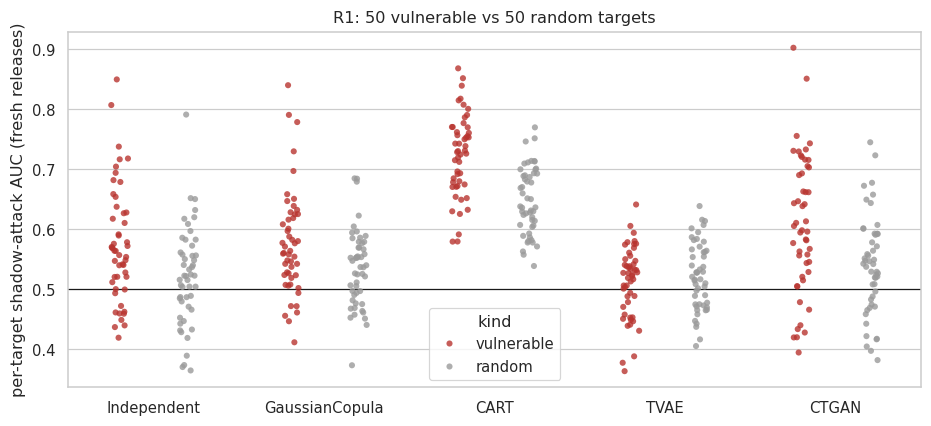

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.stripplot(data=R1, x="generator", y="auc", hue="kind", dodge=True, ax=ax, palette={"vulnerable": "#b8342f", "random": "#9a9a9a"}, size=4, alpha=0.8)
ax.axhline(0.5, c="k", lw=0.8); ax.set_ylabel("per-target shadow-attack AUC (fresh releases)"); ax.set_xlabel(""); ax.set_title("R1: 50 vulnerable vs 50 random targets")
fig.savefig(f"{OUT}/figures/R1_targets100.png"); plt.show()

## R2. Canary-based DP audit
The canary is a record built to be as distinctive as possible inside the public domain: age 90, hours 99, education "Preschool",
marital status "Married-AF-spouse", race "Other", sex "Female", income ">50K". Any identical record is removed from the pool.
40 shadow releases pick the attack threshold; 160 fresh releases (80 with the canary, 80 without) measure FPR and FNR, so the
audit can certify at most ε ≈ 3.0.

Two MST variants are audited. **Public domain**: the category lists come from the public schema (the correct DP setup).
**Data domain**: the category lists are read from the private training data, which is what SmartNoise does when no fitted
transformer is supplied, and what Part I and Notebooks 01–05 used. If a rare category appears only when the canary is
present, the data-domain variant leaks it regardless of ε.

In [4]:
cols7 = ["age", "education", "marital_status", "race", "sex", "hours_per_week", "income"]
m7 = dict(meta); m7["num"] = ["age", "hours_per_week"]; m7["cat"] = [c for c in cols7 if c not in m7["num"]]
m7["bounds"] = {c: meta["bounds"][c] for c in m7["num"]}; m7["int_cols"] = m7["num"]; m7["qi"] = ["age", "sex", "race", "marital_status"]
m7["_qbins"] = {c: qb[c] for c in m7["num"]}; m7["domains"] = {c: meta["domains"][c] for c in m7["cat"]}
canary = pd.Series(dict(age=90.0, education="Preschool", marital_status="Married-AF-spouse", race="Other", sex="Female", hours_per_week=99.0, income=">50K"))
pool7 = df[cols7]; pool7 = pool7[~(pool7 == canary.values).all(axis=1)].reset_index(drop=True)
subs7 = [list(np.random.RandomState(s).choice(cols7, np.random.RandomState(s).randint(1, 4), replace=False)) for s in range(20)]
NS, NE = (40, 160) if not QUICK else (6, 8)
def audit(name, eps):
    gen = {"CART": sa.gen_cart, "Independent": sa.gen_independent}.get(name, sa.gen_mst)
    kw = {} if name in ("CART", "Independent") else dict(eps=eps, iters_cap=1000, public_domain=(name == "MST (public domain)"))
    r = sa.shadow_attack(gen, pool7, canary, m7, 500, NS, NE, seed=11, subsets=subs7, **kw)
    thr = max(np.unique(r["train_scores"]), key=lambda t: sa.eps_lb_at(r["train_scores"], r["train_labels"], t))
    pred = r["scores"] >= thr
    return dict(mechanism=name, eps_nominal=eps, auc=r["auc"], bb_auc=r["bb_auc"], tpr=float(pred[r["labels"] == 1].mean()), fpr=float(pred[r["labels"] == 0].mean()),
                eps_lb=sa.eps_lb_at(r["scores"], r["labels"], thr), eps_lb_ceiling=sa.eps_lb_at(r["labels"].astype(float), r["labels"], 0.5), n_eval=len(r["labels"]))
t0 = time.time()
AUD = pd.DataFrame(Parallel(n_jobs=2)(delayed(audit)(n, e) for n, e in [("MST (public domain)", 1.0), ("MST (public domain)", 10.0), ("MST (public domain)", 100.0),
                                                                      ("MST (data domain)", 1.0), ("CART", np.inf), ("Independent", np.inf)]))
AUD.to_csv(f"{T}/R2_canary_audit.csv", index=False); print(f"audit {(time.time()-t0)/60:.1f} min"); AUD.round(3)

audit 67.9 min


,mechanism,eps_nominal,auc,bb_auc,tpr,fpr,eps_lb,eps_lb_ceiling,n_eval
0,MST (public domain),1.0,0.613,0.440,0.988,0.988,0.000,3.054,160
1,MST (public domain),10.0,0.566,0.588,1.000,1.000,0.000,3.054,160
2,MST (public domain),100.0,0.807,0.782,0.988,0.950,0.000,3.054,160
3,MST (data domain),1.0,0.879,0.639,0.925,0.325,1.279,3.054,160
4,CART,inf,0.805,0.789,0.375,0.038,0.935,3.054,160
5,Independent,inf,0.758,0.561,1.000,0.962,0.000,3.054,160


## R3. The transformer on small tables: is memorisation a model-size problem?

In [5]:
R3 = []
for key in (["german", "pima"] if not QUICK else ["german"]):
    dk, mk = sa.load(key)
    for seed in ([0, 1, 2] if not QUICK else [0]):
        tr, ho, te = sa.make_split(dk, mk, seed); u_r, p_r = sa.utility(tr, te, mk, seed); real = (u_r, sa.fairness(tr, te, p_r["HGB"], mk))
        for steps in ([150, 300, 750, 1500] if not QUICK else [20, 40]):
            syn = sa.postprocess(sa.gen_ar(tr, mk, seed, steps=steps), tr, mk)
            r, _ = sa.evaluate_release(tr, ho, te, syn, mk, seed, real=real)
            R3.append(dict(dataset=mk["name"], seed=seed, steps=steps, util_ratio=r["util_ratio"], pair=r["pair"], mia_auc=r["mia_auc_max"],
                           tpr1=r["mia_tpr1_max"], link=r["anon_link"], exact=r["exact_match_syn"]))
            print(f"{mk['name']:<7} s{seed} steps={steps:<5} U={r['util_ratio']:.3f} MIA={r['mia_auc_max']:.3f} TPR1={r['mia_tpr1_max']:.3f} link={r['anon_link']:.3f}", flush=True)
R3 = pd.DataFrame(R3); R3.to_csv(f"{T}/R3_ar_small.csv", index=False)
R3.groupby(["dataset", "steps"])[["util_ratio", "pair", "mia_auc", "tpr1", "link", "exact"]].mean().round(3)

German  s0 steps=150   U=0.957 MIA=0.583 TPR1=0.052 link=0.000


German  s0 steps=300   U=0.964 MIA=0.616 TPR1=0.045 link=0.142


German  s0 steps=750   U=0.988 MIA=0.764 TPR1=0.470 link=0.477


German  s0 steps=1500  U=0.978 MIA=0.804 TPR1=0.555 link=0.621


German  s1 steps=150   U=0.925 MIA=0.578 TPR1=0.040 link=0.000


German  s1 steps=300   U=0.988 MIA=0.613 TPR1=0.048 link=0.223


... (15 outputs left out)

Pima    s2 steps=300   U=0.980 MIA=0.734 TPR1=0.450 link=0.563


Pima    s2 steps=750   U=0.948 MIA=0.771 TPR1=0.564 link=0.644


Pima    s2 steps=1500  U=0.971 MIA=0.760 TPR1=0.528 link=0.535


util_ratio   pair  mia_auc   tpr1   link  exact
dataset steps                                                 
German  150         0.933  0.930    0.585  0.037  0.017  0.000
        300         0.969  0.926    0.620  0.057  0.172  0.001
        750         0.954  0.934    0.760  0.472  0.530  0.016
        1500        0.979  0.937    0.801  0.573  0.608  0.022
Pima    150         0.950  0.801    0.606  0.049  0.179  0.000
        300         0.966  0.830    0.741  0.448  0.556  0.007
        750         0.964  0.832    0.782  0.550  0.618  0.004
        1500        0.985  0.825    0.767  0.533  0.565  0.004

## R4. A fair augmentation test inside the generators' operating range
Adult; n = 500, 1,000 and 2,500 real training rows; the generator is fitted on those rows and adds synthetic rows equal to
0.5×, 1× or 2× n. Test AUC is the mean of LR, RF and HGB on a fixed 5,000-row real test set; 3 seeds.

In [6]:
R4 = []; GENS4 = ["GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM", "AR-Transformer"] if not QUICK else ["CART"]
for seed in ([0, 1, 2] if not QUICK else [0]):
    tr_full, _, te = sa.make_split(df, meta, seed)
    for n in ([500, 1000, 2500] if not QUICK else [500]):
        tr = tr_full.sample(n, random_state=seed).reset_index(drop=True)
        base = sa.utility(tr, te, meta, seed)[0]["auc_mean"]; R4.append(dict(seed=seed, n=n, generator="—", ratio=0.0, auc=base))
        for g in GENS4:
            t0 = time.time(); pool = sa.postprocess(sa.GENERATORS[g](tr, meta, seed, n=2 * n), tr, meta)
            for ratio in [0.5, 1.0, 2.0]:
                aug = pd.concat([tr, pool.iloc[: int(ratio * n)]], ignore_index=True)
                R4.append(dict(seed=seed, n=n, generator=g, ratio=ratio, auc=sa.utility(aug, te, meta, seed)[0]["auc_mean"]))
            print(f"s{seed} n={n} {g:<15} | {time.time()-t0:.0f}s", flush=True)
        pd.DataFrame(R4).to_csv(f"{T}/R4_fair_augmentation.csv", index=False)
R4 = pd.DataFrame(R4)
b = R4[R4.generator == "—"][["seed", "n", "auc"]].rename(columns={"auc": "base"})
G4 = R4[R4.generator != "—"].merge(b, on=["seed", "n"]); G4["gain"] = G4.auc - G4.base
t4 = G4.groupby(["generator", "n", "ratio"]).gain.agg(["mean", sa.ci_t]).rename(columns={"mean": "gain", "ci_t": "ci"})
t4["significant_gain"] = (t4.gain - t4.ci) > 0; t4.to_csv(f"{T}/R4_gains.csv"); display(t4.round(4))
print("configurations with a significant gain:", int(t4.significant_gain.sum()), "of", len(t4))

s0 n=500 GaussianCopula  | 3s


s0 n=500 CART            | 3s


s0 n=500 CTGAN           | 21s


s0 n=500 TVAE            | 7s


s0 n=500 DDPM            | 143s


s0 n=500 AR-Transformer  | 98s


... (46 outputs left out)

s2 n=2500 DDPM            | 137s


s2 n=2500 AR-Transformer  | 103s


gain      ci  significant_gain
generator      n    ratio                                  
AR-Transformer 500  0.5   -0.0020  0.0069             False
                    1.0   -0.0051  0.0048             False
                    2.0   -0.0070  0.0106             False
               1000 0.5   -0.0025  0.0011             False
                    1.0   -0.0037  0.0012             False
                    2.0   -0.0040  0.0021             False
               2500 0.5   -0.0014  0.0005             False
                    1.0   -0.0029  0.0025             False
                    2.0   -0.0041  0.0029             False
CART           500  0.5   -0.0070  0.0066             False
                    1.0   -0.0059  0.0085             False
                    2.0   -0.0071  0.0090             False
               1000 0.5   -0.0039  0.0088             False
                    1.0   -0.0040  0.0059             False
                    2.0   -0.0048  0.0069             False
               2500 0.5   -0.0015  0.0011             False
                    1.0   -0.0029  0.0055             False
                    2.0   -0.0034  0.0049             False
CTGAN          500  0.5   -0.0104  0.0107             False
                    1.0   -0.0182  0.0086             False
                    2.0   -0.0228  0.0151             False
               1000 0.5   -0.0105  0.0084             False
                    1.0   -0.0183  0.0122             False
                    2.0   -0.0298  0.0089             False
               2500 0.5   -0.0059  0.0007             False
                    1.0   -0.0097  0.0020             False
                    2.0   -0.0175  0.0065             False
DDPM           500  0.5   -0.0136  0.0043             False
                    1.0   -0.0164  0.0059             False
                    2.0   -0.0211  0.0029             False
               1000 0.5   -0.0094  0.0098             False
                    1.0   -0.0110  0.0087             False
                    2.0   -0.0116  0.0129             False
               2500 0.5   -0.0063  0.0029             False
                    1.0   -0.0094  0.0001             False
                    2.0   -0.0118  0.0044             False
GaussianCopula 500  0.5   -0.0058  0.0069             False
                    1.0   -0.0077  0.0091             False
                    2.0   -0.0095  0.0048             False
               1000 0.5   -0.0079  0.0037             False
                    1.0   -0.0104  0.0039             False
                    2.0   -0.0160  0.0100             False
               2500 0.5   -0.0106  0.0097             False
                    1.0   -0.0133  0.0112             False
                    2.0   -0.0164  0.0117             False
TVAE           500  0.5   -0.0023  0.0110             False
                    1.0   -0.0049  0.0104             False
                    2.0   -0.0077  0.0095             False
               1000 0.5   -0.0034  0.0021             False
                    1.0   -0.0042  0.0047             False
                    2.0   -0.0058  0.0078             False
               2500 0.5   -0.0013  0.0007             False
                    1.0   -0.0023  0.0027             False
                    2.0   -0.0043  0.0033             False

configurations with a significant gain: 0 of 54


## Re-analysis of Part I's scarcity experiment (E5) by operating regime

In [7]:
E5 = pd.read_csv("partI_E5_scarcity.csv")
bb = E5[E5.condition == "real only"][["seed", "n", "auc"]].rename(columns={"auc": "base"})
A = E5[E5.condition == "real + synthetic"].merge(bb, on=["seed", "n"]); A["gain"] = A.auc - A.base
A["regime"] = np.where(A.n >= 500, "operating range (n ≥ 500)", "below operating range (n ≤ 250)")
reg = A.groupby(["regime", "generator"]).gain.agg(["mean", sa.ci_t, "size"]).round(4); reg.to_csv(f"{T}/R4_E5_by_regime.csv"); display(reg)
print(f"Notebook runtime: {(time.time()-T0)/60:.1f} min")

mean    ci_t  size
regime                          generator                           
below operating range (n ≤ 250) CART           -0.0473  0.0231     9
                                CTGAN          -0.1643  0.0517     9
                                GaussianCopula -0.0382  0.0213     9
                                TVAE           -0.0482  0.0368     9
operating range (n ≥ 500)       CART           -0.0067  0.0025     9
                                CTGAN          -0.0473  0.0191     9
                                GaussianCopula -0.0189  0.0044     9
                                TVAE           -0.0100  0.0054     9

Notebook runtime: 180.7 min
